In [30]:
import pandas as pd

filepath = "../data/dataset.xlsx"

dataframe = pd.read_excel(filepath)

#dataframe.head()

In [31]:
# Initial data checks
dataframe.shape # Shows the data type for each column (feature)

hasNullValues = dataframe.isnull().sum() # Checks for NaN or None, but NOT " "
#print(hasNullValues)

hasDuplications = dataframe.duplicated().sum() # Checks for duplicate rows
#print(f"Dataframe has: {hasDuplications} duplications")

dataframe.dtypes

statistics = dataframe.describe(include="all") # Prints typical statistical values such as mean, std, count (# of rows)
display(statistics)

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
count,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.00000,319.000000,...,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000
mean,0.495298,48.068966,0.492163,0.335423,0.037618,0.028213,0.025078,0.134796,167.15674,80.564890,...,49.475549,144.502163,21.684953,26.855799,73.112539,0.800611,100.818903,1.853856,14.418182,21.401411
std,0.500763,12.114558,0.500724,0.517340,0.190568,0.165841,0.156609,0.342042,10.05303,15.709069,...,17.718701,97.904493,16.697605,27.884413,24.181069,0.176433,16.971396,4.989591,1.775815,9.981659
min,0.000000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,145.00000,42.900000,...,25.000000,1.390000,8.000000,3.000000,7.000000,0.460000,10.600000,0.000000,8.500000,3.500000
25%,0.000000,38.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,159.50000,69.600000,...,40.000000,83.000000,15.000000,14.250000,58.000000,0.650000,94.170000,0.000000,13.300000,13.250000
50%,0.000000,49.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,168.00000,78.800000,...,46.500000,119.000000,18.000000,19.000000,71.000000,0.790000,104.000000,0.215000,14.400000,22.000000
75%,1.000000,56.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,175.00000,91.250000,...,56.000000,172.000000,23.000000,30.000000,86.000000,0.920000,110.745000,1.615000,15.700000,28.060000
max,1.000000,96.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000,191.00000,143.500000,...,273.000000,838.000000,195.000000,372.000000,197.000000,1.460000,132.000000,43.400000,18.800000,53.100000


In [32]:
# FEATURES THAT SEEM OK BASED ON COMMON SENSE - without a medical degree!
# Gallstone status, age, gender, CAD, Hypothyroidism, Hyperlipidemia ,Diabetes Mellitus (DM)
# Height, Weight,Body Mass Index (BMI),	Total Body Water, Extracellular Water (ECW)
# Intracellular Water (ICW), Extracellular Fluid/Total Body Water (ECF/TBW)
# Total Body Fat Ratio (TBFR) (%), Lean Mass (LM) (%), Body Protein Content (Protein) (%)
# Visceral Fat Rating (VFR), Bone Mass (BM), Muscle Mass (MM, Visceral Fat Area (VFA)
# Visceral Muscle Area (VMA) (Kg), Hepatic Fat Accumulation (HFA)

In [33]:
# Comorbidity is explained in the docs:  Comorbidity: 0 (No comorbidities present),1 (One comorbid condition), 2 (Two comorbid conditions), 3 (Three or more comorbid conditions)

In [34]:

# DATA THAT SEEM A BIT SUSPICIOUS AT FIRST GLANCE
# Comorbidity is a binary 0 / 1 according to the intro paper
# Obesity (%) 
# Very high max: Glucose,  Low Density Lipoprotein (LDL
# Total Cholesterol (TC), High Density Lipoprotein (HDL)
# Triglyceride, Aspartat Aminotransferaz (AST)
# Alanin Aminotransferaz (ALT), Alkaline Phosphatase (ALP)
# C-Reactive Protein (CRP)

features = [
    'Obesity (%)',
    'Glucose',
    'Low Density Lipoprotein (LDL)',
    'Total Fat Content (TFC)',
    'High Density Lipoprotein (HDL)',
    'Triglyceride',
    'Aspartat Aminotransferaz (AST)',
    'Alanin Aminotransferaz (ALT)',
    'Alkaline Phosphatase (ALP)',
    'C-Reactive Protein (CRP)'
]

dataframe[features].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T

,count,mean,std,min,25%,50%,75%,95%,99%,max
Obesity (%),319.0,35.850125,109.799718,0.40,13.90,25.600,41.750,72.060,96.4518,1954.0
Glucose,319.0,108.688715,44.848714,69.00,92.00,98.000,109.000,168.000,317.6200,575.0
Low Density Lipoprotein (LDL),319.0,126.652351,38.541175,11.00,100.50,122.000,151.000,194.000,223.4600,293.0
Total Fat Content (TFC),319.0,23.487774,9.607607,3.10,17.00,22.600,28.550,40.640,50.3280,62.5
High Density Lipoprotein (HDL),319.0,49.475549,17.718701,25.00,40.00,46.500,56.000,73.000,85.2800,273.0
Triglyceride,319.0,144.502163,97.904493,1.39,83.00,119.000,172.000,316.400,462.3800,838.0
Aspartat Aminotransferaz (AST),319.0,21.684953,16.697605,8.00,15.00,18.000,23.000,39.100,66.5600,195.0
Alanin Aminotransferaz (ALT),319.0,26.855799,27.884413,3.00,14.25,19.000,30.000,64.000,102.8200,372.0
Alkaline Phosphatase (ALP),319.0,73.112539,24.181069,7.00,58.00,71.000,86.000,115.000,143.2000,197.0
C-Reactive Protein (CRP),319.0,1.853856,4.989591,0.00,0.00,0.215,1.615,7.047,29.8300,43.4


In [35]:
dataframe.loc[dataframe['Comorbidity'] > 1.0]

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
14,0,59,0,3,1,0,0,0,176,68.4,...,38.0,190.0,17.0,18.0,70.0,0.78,102.73,0.26,15.6,41.50
15,0,55,0,2,0,0,0,1,170,87.1,...,36.0,77.0,15.0,24.0,24.0,0.89,100.58,0.16,16.4,51.40
16,0,49,0,3,1,0,0,0,177,90.3,...,35.0,249.0,17.0,20.0,47.0,0.99,93.38,1.46,15.5,43.34


In [36]:
dataframe.loc[
    dataframe['Obesity (%)'] > 70,
    ['Obesity (%)', 'Body Mass Index (BMI)',
     'Total Body Fat Ratio (TBFR) (%)',
     'Weight', 'Height']
]  

,Obesity (%),Body Mass Index (BMI),Total Body Fat Ratio (TBFR) (%),Weight,Height
23,125.60,49.7,42.30,143.5,170
83,83.10,40.3,49.80,100.5,158
90,80.80,39.7,43.60,104.3,162
95,78.20,39.2,42.00,105.5,164
131,73.90,38.3,38.30,80.5,145
134,76.30,38.8,40.30,105.6,165
151,72.60,38.0,40.80,102.2,164
152,72.00,37.8,38.10,82.9,148
194,70.50,37.5,33.30,116.1,176
200,85.80,40.9,34.20,104.6,160



Obesity (%)
count     319.000000
mean       35.850125
std       109.799718
min         0.400000
25%        13.900000
50%        25.600000
75%        41.750000
max      1954.000000
Name: Obesity (%), dtype: float64


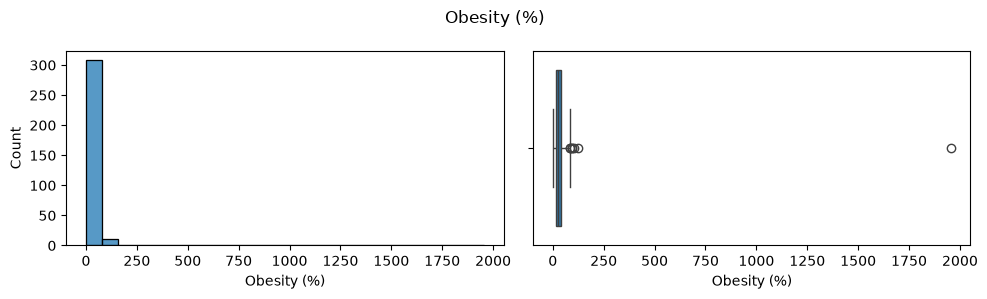


Glucose
count    319.000000
mean     108.688715
std       44.848714
min       69.000000
25%       92.000000
50%       98.000000
75%      109.000000
max      575.000000
Name: Glucose, dtype: float64


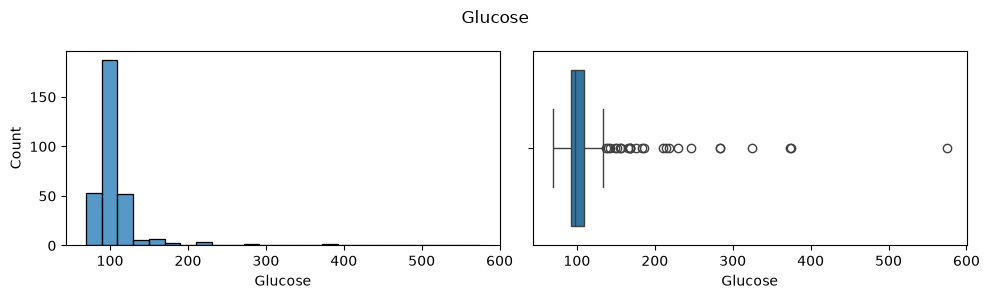


Triglyceride
count    319.000000
mean     144.502163
std       97.904493
min        1.390000
25%       83.000000
50%      119.000000
75%      172.000000
max      838.000000
Name: Triglyceride, dtype: float64


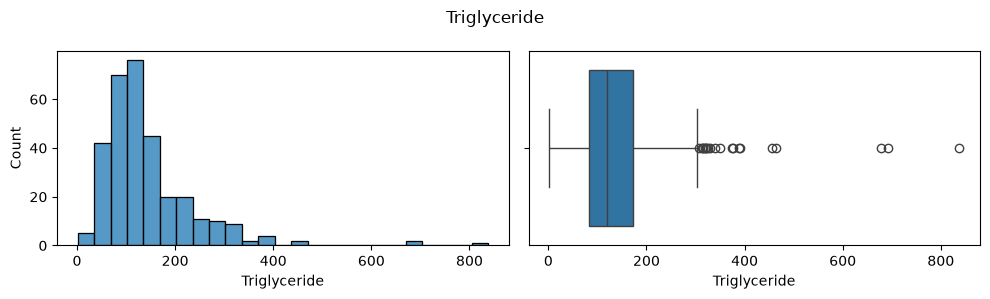

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = ["Obesity (%)", "Glucose", "Triglyceride"]

for col in columns:
    print(f"\n{col}")
    print(dataframe[col].describe())

    fig, axes = plt.subplots(1, 2, figsize=(10, 3))

    sns.histplot(dataframe[col], bins=25, ax=axes[0])
    sns.boxplot(x=dataframe[col], ax=axes[1])

    plt.suptitle(col)
    plt.tight_layout()
    plt.show()

,Height,Weight,Obesity (%)
239,150,65.9,1954.00
23,170,143.5,125.60
209,150,102.1,106.30
280,150,108.4,96.63
246,162,125.8,95.64
293,172,121.0,85.90
200,160,104.6,85.80
83,158,100.5,83.10
258,157,109.2,80.82
90,162,104.3,80.80


['Gallstone Status', 'Age', 'Gender', 'Comorbidity', 'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia', 'Diabetes Mellitus (DM)', 'Height', 'Weight', 'Body Mass Index (BMI)', 'Total Body Water (TBW)', 'Extracellular Water (ECW)', 'Intracellular Water (ICW)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)', 'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)', 'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)', 'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)', 'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)', 'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)', 'High Density Lipoprotein (HDL)', 'Triglyceride', 'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)', 'Alkaline Phosphatase (ALP)', 'Creatinine', 'Glomerular Filtration Rate (GFR)', 'C-Reactive Protein (CRP)', 'Hemoglobin (HGB)', 'Vitamin D']


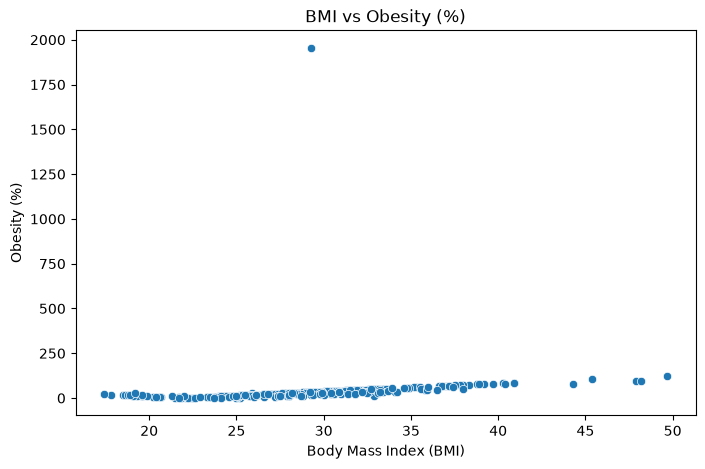

In [38]:
# Show the 10 largest obesity values
columns = [
    "Height",
    "Weight",
    "Obesity (%)"
]

display(
    dataframe.nlargest(10, "Obesity (%)")[columns]
)
print(dataframe.columns.tolist())

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=dataframe,
    x="Body Mass Index (BMI)",
    y="Obesity (%)"
)

plt.title("BMI vs Obesity (%)")
plt.show()

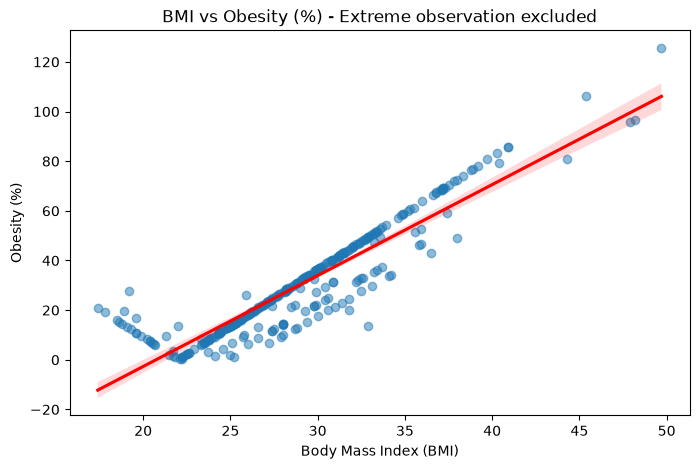

In [39]:
df_plot = dataframe[dataframe["Obesity (%)"] < 500]

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_plot,
    x="Body Mass Index (BMI)",
    y="Obesity (%)",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("BMI vs Obesity (%) - Extreme observation excluded")
plt.show()

In [40]:
from sklearn.model_selection import train_test_split
# Overfitting occurs when a model learns the training data
# too closely, including noise, rather than general patterns.
#
# Split the dataset into training and testing sets.
# Train the model on the training set.
# Evaluate its performance on previously unseen test data.

# X contains all features except the target
X = dataframe.drop(columns=['Gallstone Status'])

# y contains the target variable
y = dataframe['Gallstone Status']


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (255, 38)
X_test: (64, 38)
y_train: (255,)
y_test: (64,)


In [41]:
# At this point, phase 1 (exploratory phase) and phase 2 (train/test split) is done
# Next step is phase 3. Data preprocessing, which includes handling missing values, sup measurements, scaling and encoding
# Phase 4 is training the models with the training data and 
# phase 5 is testing the models with metrics etc